# 01 - Exploratory data analysis
Hourly PM2.5, other pollutants and weather for 10 Indian cities (Open-Meteo / CAMS / ERA5).

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from ml.config import FIG_DIR, PROC_DIR, REPORT_DIR, MODEL_DIR
sns.set_theme(style='whitegrid')
def save(name): plt.tight_layout(); plt.savefig(FIG_DIR / name, dpi=130); plt.show()
df = pd.read_parquet(PROC_DIR / 'clean.parquet')
df['month'] = df.timestamp.dt.month; df['hour'] = df.timestamp.dt.hour; df['year'] = df.timestamp.dt.year
df['season'] = df.month.map(lambda m: 'Winter' if m in (11,12,1,2) else 'Monsoon' if m in (6,7,8,9) else 'Other')
df.shape, df.timestamp.min(), df.timestamp.max()

((366420, 24),
 Timestamp('2022-08-04 05:00:00'),
 Timestamp('2026-10-08 22:00:00'))

## 1. Missing values and gaps

In [2]:
print(df.groupby('city').size().to_frame('rows').join(df.groupby('city').pm2_5.apply(lambda s: s.isna().sum()).rename('missing_pm25')))
df[['pm2_5','pm10','nitrogen_dioxide','temperature_2m','wind_speed_10m']].describe().round(1)

            rows  missing_pm25
city                          
Ahmedabad  36642             0
Bengaluru  36642             0
Chennai    36642             0
Delhi      36642             0
Hyderabad  36642             0
Kolkata    36642             0
Lucknow    36642             0
Mumbai     36642             0
Nagpur     36642             0
Pune       36642             0


,pm2_5,pm10,nitrogen_dioxide,temperature_2m,wind_speed_10m
count,366420.0,366420.0,366420.0,366420.0,366420.0
mean,39.4,63.3,19.9,26.3,9.7
std,34.4,72.6,22.4,5.5,5.1
min,0.2,0.2,0.0,3.2,0.0
25%,17.2,26.4,6.3,23.1,6.1
50%,29.3,44.4,12.1,26.5,8.8
75%,50.3,74.3,24.1,29.6,12.6
max,581.1,1989.3,295.2,46.5,53.1


## 2. PM2.5 distribution (log scale)

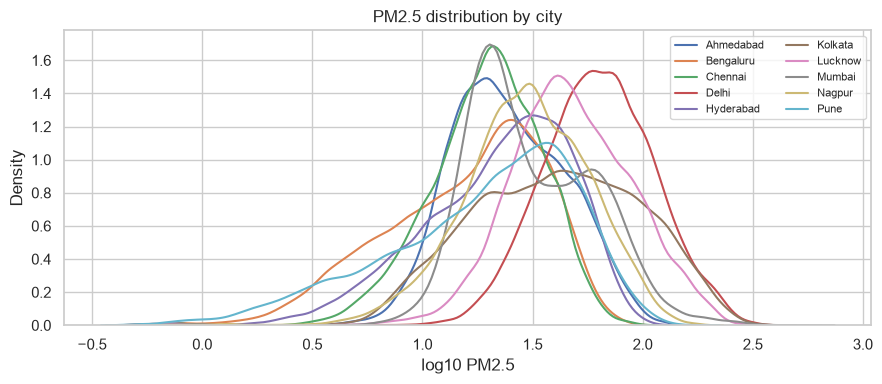

In [3]:
fig, ax = plt.subplots(figsize=(9,4))
for c, g in df.groupby('city'): sns.kdeplot(np.log10(g.pm2_5.clip(lower=0.5)), ax=ax, label=c)
ax.set_xlabel('log10 PM2.5'); ax.legend(ncol=2, fontsize=8); ax.set_title('PM2.5 distribution by city'); save('eda_01_distribution.png')

## 3. Monthly pattern per city

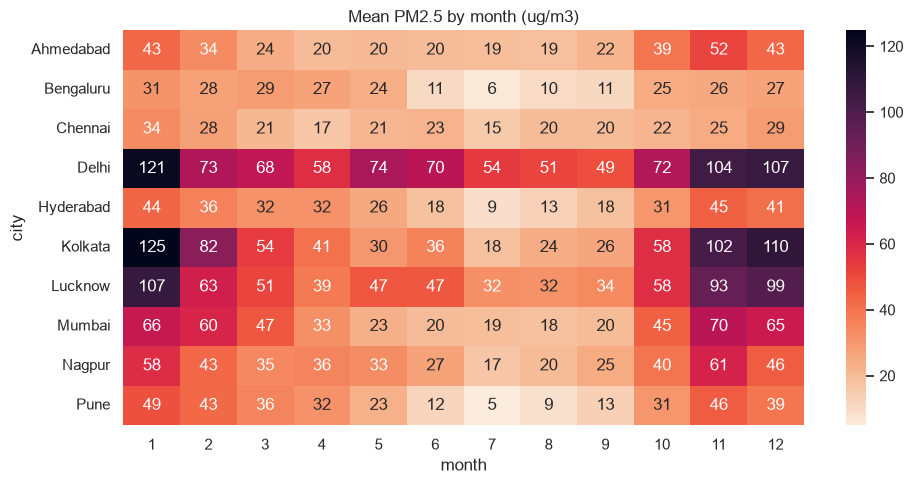

In [4]:
m = df.pivot_table(index='month', columns='city', values='pm2_5'); plt.figure(figsize=(10,5)); sns.heatmap(m.T, cmap='rocket_r', annot=True, fmt='.0f')
plt.title('Mean PM2.5 by month (ug/m3)'); save('eda_02_monthly_heatmap.png')

## 4. Hour-of-day pattern and weekday vs weekend

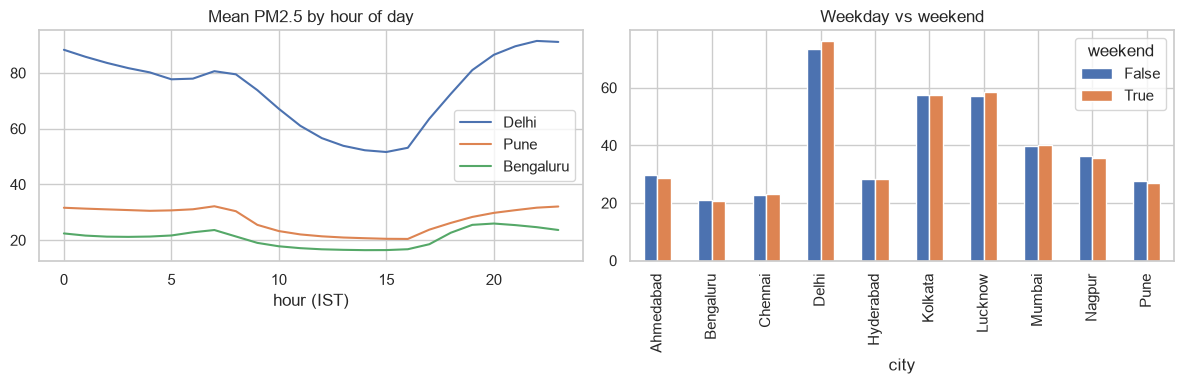

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
for c in ['Delhi','Pune','Bengaluru']:
    ax[0].plot(df[df.city==c].groupby('hour').pm2_5.mean(), label=c)
ax[0].set_title('Mean PM2.5 by hour of day'); ax[0].legend(); ax[0].set_xlabel('hour (IST)')
wk = df.assign(weekend=df.timestamp.dt.dayofweek>=5).groupby(['city','weekend']).pm2_5.mean().unstack(); wk.plot.bar(ax=ax[1]); ax[1].set_title('Weekday vs weekend')
save('eda_03_hourly_weekend.png')

## 5. Seasonality: monsoon vs winter

season     Monsoon  Winter  winter/monsoon
city                                      
Ahmedabad     20.1    43.1             2.1
Bengaluru      9.6    28.0             2.9
Chennai       19.5    29.1             1.5
Delhi         55.5   101.9             1.8
Hyderabad     14.8    41.7             2.8
Kolkata       26.1   105.3             4.0
Lucknow       36.0    91.2             2.5
Mumbai        19.3    65.4             3.4
Nagpur        22.4    52.2             2.3
Pune           9.8    44.1             4.5


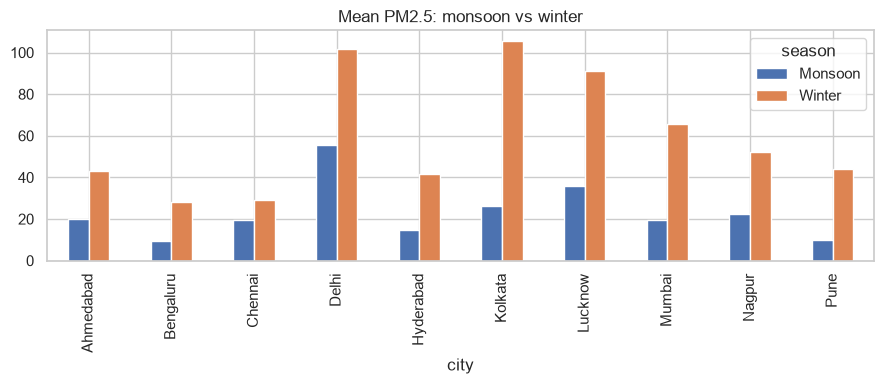

In [6]:
s = df[df.season!='Other'].groupby(['city','season']).pm2_5.mean().unstack(); s['winter/monsoon'] = s.Winter/s.Monsoon
print(s.round(1))
s[['Monsoon','Winter']].plot.bar(figsize=(9,4), title='Mean PM2.5: monsoon vs winter'); save('eda_04_season.png')

## 6. Correlation with weather and other pollutants

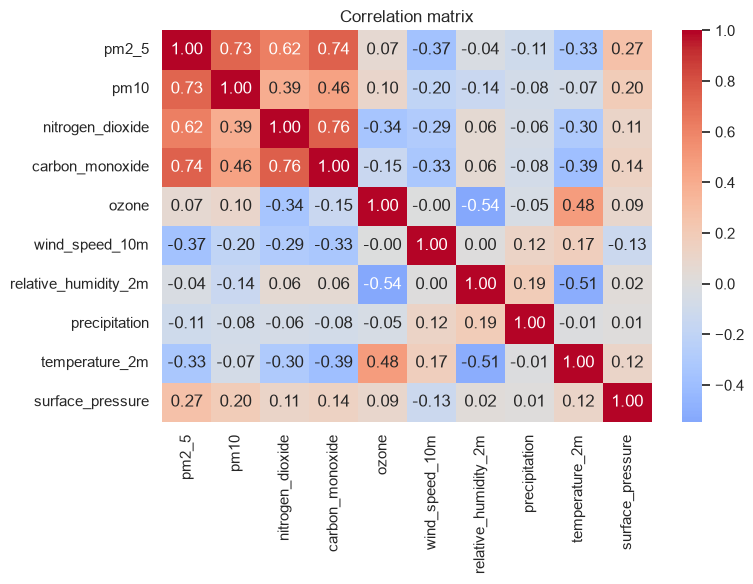

In [7]:
cols = ['pm2_5','pm10','nitrogen_dioxide','carbon_monoxide','ozone','wind_speed_10m','relative_humidity_2m','precipitation','temperature_2m','surface_pressure']
plt.figure(figsize=(8,6)); sns.heatmap(df[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0); plt.title('Correlation matrix'); save('eda_05_correlation.png')

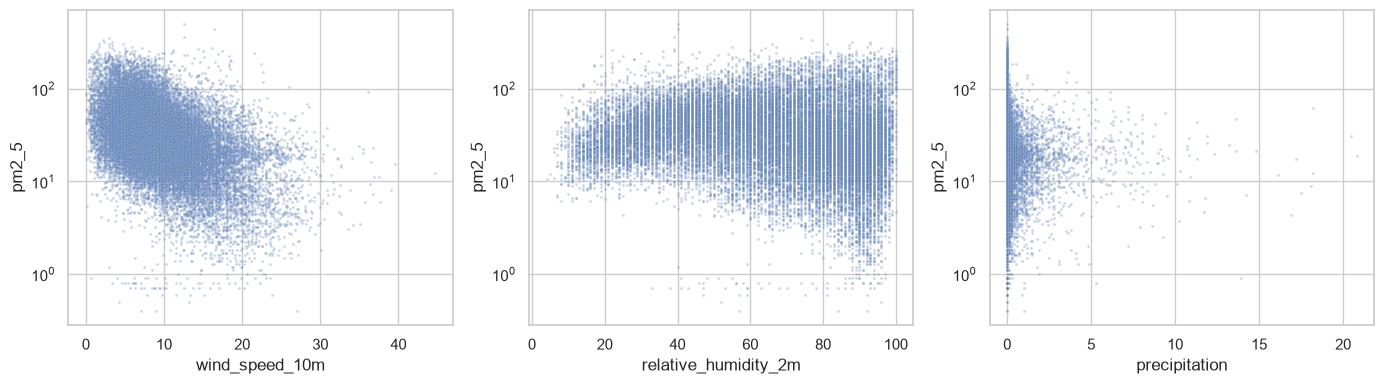

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(14,4)); d = df.sample(30000, random_state=42)
for a, c in zip(ax, ['wind_speed_10m','relative_humidity_2m','precipitation']): sns.scatterplot(data=d, x=c, y='pm2_5', s=4, alpha=.3, ax=a); a.set_yscale('log')
save('eda_06_weather_scatter.png')

## 7. Year-over-year trend

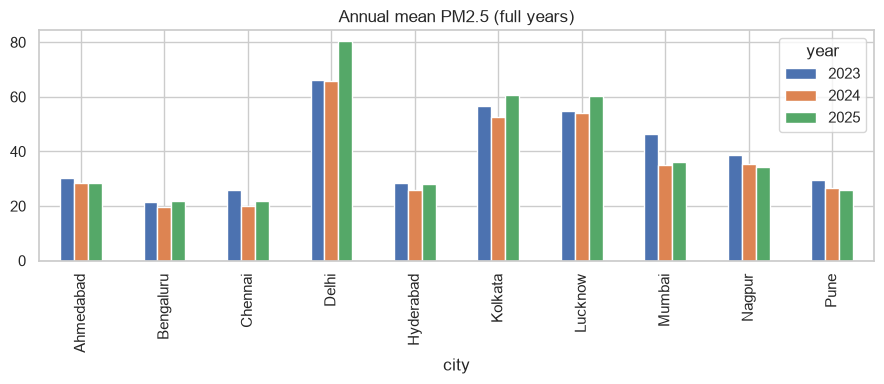

In [9]:
y = df[df.year.between(2023, 2025)].pivot_table(index='city', columns='year', values='pm2_5'); y.plot.bar(figsize=(9,4), title='Annual mean PM2.5 (full years)'); save('eda_07_yearly.png')

## 8. Extreme-pollution events (top 1% hours)

99th percentile: 175.1


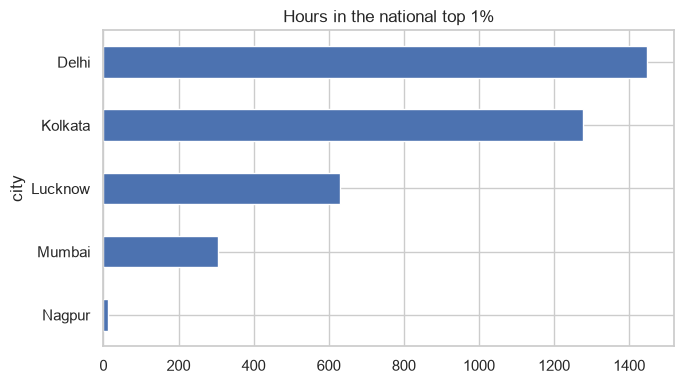

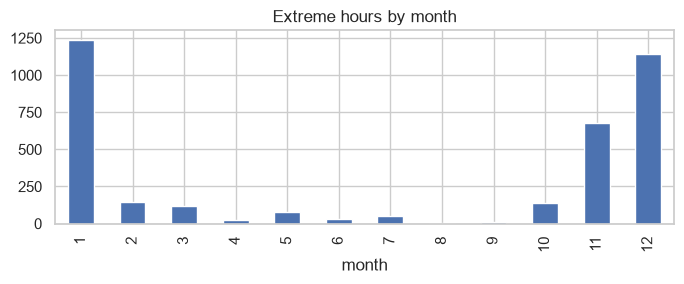

In [10]:
thr = df.pm2_5.quantile(.99); ex = df[df.pm2_5 >= thr]; print('99th percentile:', round(thr,1))
ex.groupby('city').size().sort_values().plot.barh(figsize=(7,4), title='Hours in the national top 1%'); save('eda_08_extremes.png')
ex.groupby('month').size().plot.bar(figsize=(7,3), title='Extreme hours by month'); save('eda_09_extreme_months.png')

## Insights
See the generated figures and the bullet list written in `reports/final_report.md` (section Data).